# 03 - Model Development, Evaluation and Selection

Run `python -m product_discontinuation.train` first. This notebook reads the saved experiment outputs; it does not retrain.

**Validation design**
- Development editions 89-92, held-out test edition 93. Edition 93 played no part in fitting, tuning, the threshold or the calibrator, but it has been inspected more than once during evaluation and diagnosis, so it should be described as held out from fitting rather than as seen only once.
- Hyperparameters tuned with expanding-window CV over editions: train 89 -> validate 90; 89-90 -> 91; 89-91 -> 92. Refit metric: PR-AUC (average precision), because the positive class is the minority and the business acts on the ranked list of at-risk products.
- Decision threshold chosen by maximising F1 on out-of-fold development predictions - not on the test set.

**Raw scores and calibrated probabilities.** Sections 1-7 compare models using **raw model scores**, as they were produced during training; those saved tables are kept on the raw scale on purpose so that the model comparison stays reproducible. The deployed app and sections 3b-3d use **calibrated probabilities** (model version 1.1.0, Platt scaling). The mapping is monotonic, so ROC-AUC, PR-AUC and the set of flagged products are the same on both scales. The raw threshold 0.103 and the calibrated threshold 0.283 are the same decision rule.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from product_discontinuation import config

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
from IPython.display import Image, display
from product_discontinuation.persistence import load_bundle, load_metadata, model_paths

H = config.PRIMARY_HORIZON
R, FIG = config.RESULTS_DIR, config.FIGURES_DIR
model_path, meta_path = model_paths(H)
meta = load_metadata(meta_path)
print(meta["model_name"], "| calibrated threshold", round(meta["decision_threshold"], 3),
      "| raw threshold", round(meta["raw_decision_threshold"], 3), "| trained", meta["trained_at"])

hist_gradient_boosting | calibrated threshold 0.283 | raw threshold 0.103 | trained 2026-11-06T11:06:24+00:00


## 1. Hyperparameter search and model selection (cross-validation)

In [2]:
cv = pd.read_csv(config.EXPERIMENTS_DIR / f"cv_results_h{H}.csv")
fold_cols = [c for c in cv if c.startswith("split")]
cv.groupby("model").head(3)[["model", "params", "mean_test_average_precision", "std_test_average_precision",
                             "mean_test_roc_auc", *fold_cols, "mean_fit_time"]].round(4)

,model,params,mean_test_average_precision,std_test_average_precision,mean_test_roc_auc,split0_test_average_precision,split1_test_average_precision,split2_test_average_precision,mean_fit_time
0,logistic_regression,"{'model__C': 0.1, 'model__class_weight': 'bala...",0.6956,0.1282,0.8333,0.8759,0.5897,0.6211,1.5937
1,logistic_regression,"{'model__C': 1.0, 'model__class_weight': 'bala...",0.6915,0.1220,0.8313,0.8636,0.5960,0.6149,2.6036
2,logistic_regression,"{'model__C': 0.1, 'model__class_weight': None}",0.6914,0.1286,0.8289,0.8724,0.5851,0.6167,1.3686
8,random_forest,"{'model__n_estimators': 200, 'model__min_sampl...",0.6858,0.0901,0.8336,0.8130,0.6168,0.6275,5.4291
9,random_forest,"{'model__n_estimators': 200, 'model__min_sampl...",0.6789,0.0863,0.8256,0.8009,0.6150,0.6208,14.4899
10,random_forest,"{'model__n_estimators': 200, 'model__min_sampl...",0.6783,0.0889,0.8264,0.8038,0.6102,0.6208,5.6575
16,hist_gradient_boosting,"{'model__min_samples_leaf': 20, 'model__max_le...",0.6988,0.1025,0.8459,0.8437,0.6300,0.6226,4.0452
17,hist_gradient_boosting,"{'model__min_samples_leaf': 100, 'model__max_l...",0.6912,0.0976,0.8413,0.8289,0.6151,0.6295,4.1852
18,hist_gradient_boosting,"{'model__min_samples_leaf': 100, 'model__max_l...",0.6911,0.1098,0.8389,0.8447,0.6343,0.5944,8.4336


In [3]:
selection = pd.read_csv(R / f"model_selection_h{H}.csv")
selection.round(4)

,model,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_balanced_accuracy,best_params
0,hist_gradient_boosting,0.6988,0.1025,0.8459,0.6384,"{'model__min_samples_leaf': 20, 'model__max_le..."
1,logistic_regression,0.6956,0.1282,0.8333,0.7138,"{'model__C': 0.1, 'model__class_weight': 'bala..."
2,random_forest,0.6858,0.0901,0.8336,0.6952,"{'model__n_estimators': 200, 'model__min_sampl..."


Per-fold scores (`split0/1/2` = editions 90/91/92) vary considerably between editions. The CV mean +/- std is the most reliable estimate of expected performance on a new edition.

## 2. Threshold selection (development data only, raw scores)

> **Scale used here: raw model scores** The thresholds in this figure and table are raw scores. The chosen raw threshold 0.103 corresponds to a calibrated probability of 0.283.

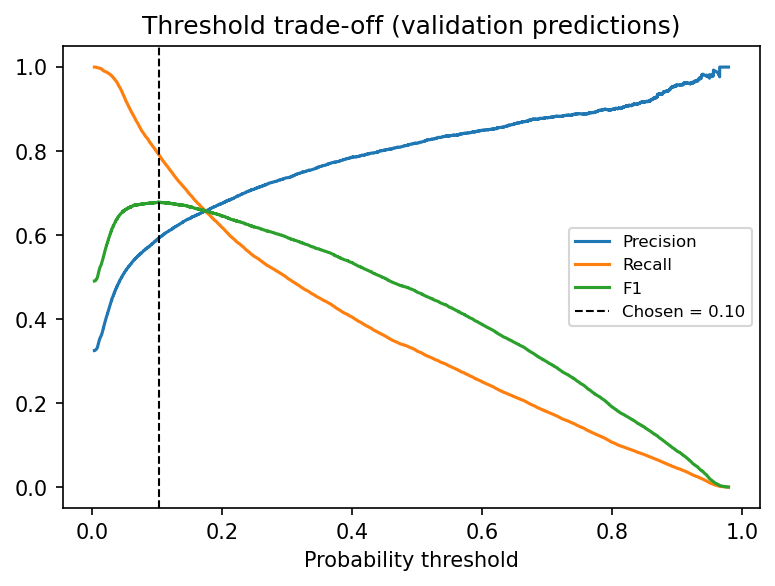

,threshold,precision,recall,f1,balanced_accuracy,tp,fp,fn,tn
0,0.2,0.676,0.617,0.645,0.737,13250,6352,8213,38228
1,0.3,0.737,0.498,0.594,0.706,10680,3820,10783,40760
2,0.4,0.786,0.404,0.534,0.676,8677,2369,12786,42211
3,0.5,0.819,0.323,0.464,0.644,6939,1534,14524,43046
4,0.6,0.849,0.250,0.387,0.614,5372,953,16091,43627
5,0.7,0.879,0.179,0.298,0.584,3843,527,17620,44053


In [4]:
display(Image(FIG / f"threshold_tradeoff_h{H}.png"))
pd.read_csv(R / f"threshold_table_validation_h{H}.csv").round(3)

**Trade-off.** A false negative (missed discontinuation) leaves Retalix holding stock of a delisted product, leading to markdowns and write-offs. A false positive wrongly flags a product that will continue; the cost is a manual review and, if acted on, lost sales. The F1-optimal threshold balances the two; if the business values early clearance more than review effort, a lower threshold (higher recall) can be selected from the table above.

## 3. Final evaluation on held-out edition 93 (raw scores)

> **Scale used here: raw model scores** `calibration_h13.png` below shows **uncalibrated** scores for the three candidate models; section 3b shows the deployed calibrated model. Confusion-matrix counts are identical on both scales.

In [5]:
test = pd.read_csv(R / f"test_metrics_h{H}.csv")
test[["model", "threshold_type", "roc_auc", "pr_auc", "precision", "recall", "f1", "balanced_accuracy", "tp", "fp", "fn", "tn"]].round(3)

,model,threshold_type,roc_auc,pr_auc,precision,recall,f1,balanced_accuracy,tp,fp,fn,tn
0,logistic_regression,selected,0.938,0.906,0.593,0.957,0.733,0.791,9331,6397,415,10640
1,random_forest,selected,0.944,0.897,0.411,0.999,0.582,0.589,9734,13977,12,3060
2,hist_gradient_boosting,selected,0.952,0.915,0.747,0.949,0.836,0.882,9246,3133,500,13904
3,logistic_regression,default_0.5,0.938,0.906,0.934,0.633,0.755,0.804,6169,434,3577,16603
4,random_forest,default_0.5,0.944,0.897,0.899,0.677,0.773,0.817,6601,739,3145,16298
5,hist_gradient_boosting,default_0.5,0.952,0.915,0.940,0.477,0.633,0.730,4652,296,5094,16741
6,baseline_status_rule (leakage benchmark),rule,0.848,0.720,0.803,0.810,0.807,0.848,7896,1934,1850,15103
7,baseline_majority_class,rule,0.500,0.364,0.000,0.000,0.000,0.500,0,0,9746,17037
8,hist_gradient_boosting_with_status (leakage in...,default_0.5,0.964,0.942,0.925,0.810,0.864,0.886,7899,642,1847,16395


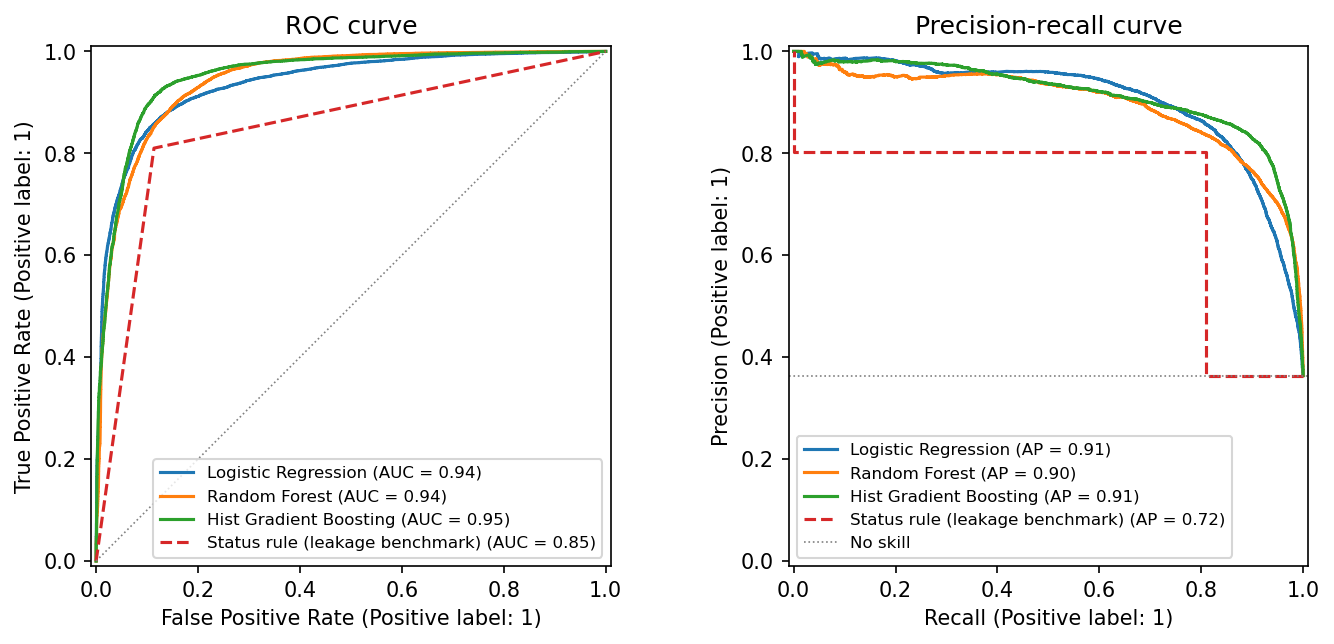

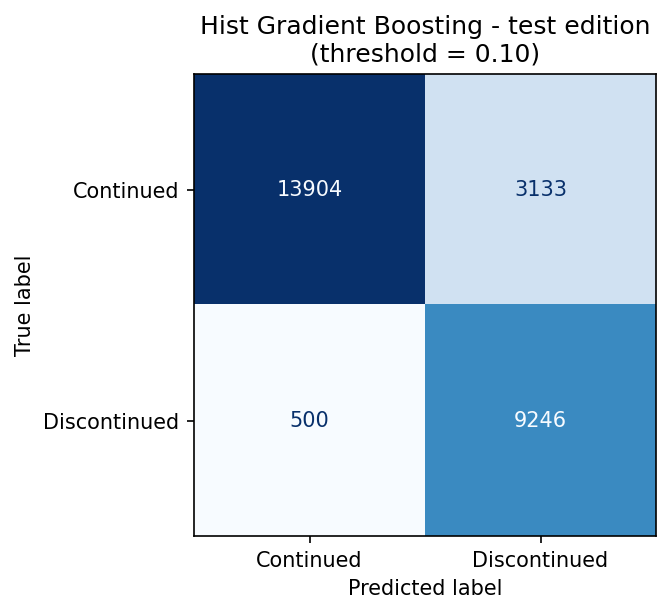

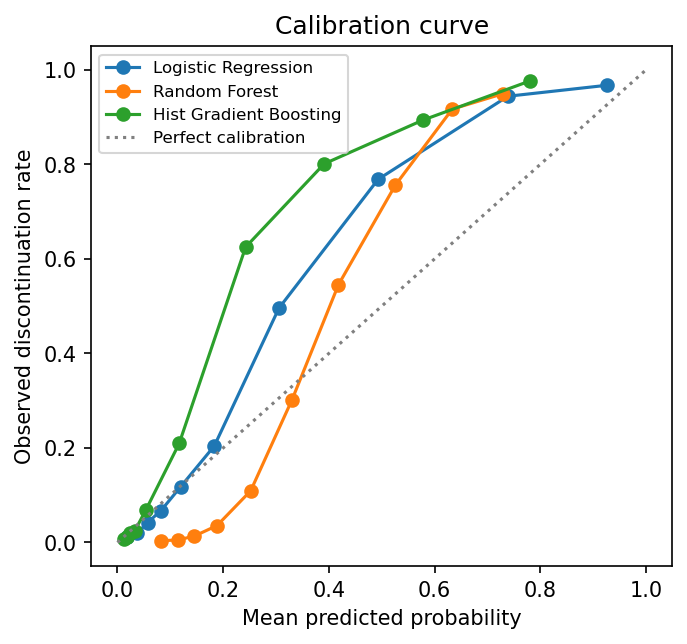

In [6]:
display(Image(FIG / f"roc_pr_curves_h{H}.png"))
display(Image(FIG / f"confusion_matrix_h{H}.png"))
display(Image(FIG / f"calibration_h{H}.png"))

**Interpretation of the measured results**
- Edition 93 scores (ROC-AUC 0.952, PR-AUC 0.915) are higher than the chronological CV mean (0.846, 0.699). Section 3d examines why; it should not be read as the expected performance on a new edition.
- The Status rule and the with-Status model are benchmarks. Status records the planners' listing decision, so it is excluded from the deployed model.
- In `calibration_h13.png` the raw-score curves lie above the diagonal: observed discontinuation is higher than the scores suggest, so raw scores understate risk. This motivated the calibration in section 3b. This was also visible on development out-of-fold predictions (mean score 0.187 against an observed rate of 0.325).

## 3b. Probability calibration (deployed model)

> **Scale used here: raw and calibrated, labelled in each row**

Platt scaling is fitted only on expanding-window out-of-fold predictions for editions 90-92. Re-running the whole fit with editions 93 and 94 removed from the raw data reproduces the saved coefficients exactly (`final_validation_h13.json`). Only metrics for edition 93 are out-of-sample for the deployed calibrator.

In [7]:
import json
cal = json.loads((R / f"calibration_h{H}.json").read_text())
final = json.loads((R / f"final_validation_h{H}.json").read_text())
print("Calibrator:", cal["calibrator"])
print("Provenance:", {k: final["calibration_provenance"][k] for k in ["oof_editions_used", "oof_rows", "max_abs_difference_a_b", "dense_rank_identical_raw_vs_calibrated"]})
rows = {"Edition 93, raw scores": cal["test_raw"], "Edition 93, calibrated": cal["test_calibrated"],
        "Development OOF, raw scores": cal["development_oof_raw"], "Development OOF, calibrated (in-sample for the calibrator)": cal["development_oof_calibrated_in_sample"]}
pd.DataFrame(rows).T.round(4)

Calibrator: {'method': 'platt', 'a': 0.9011334166857777, 'b': 1.0177032058024367}
Provenance: {'oof_editions_used': [90, 91, 92], 'oof_rows': 66043, 'max_abs_difference_a_b': 0.0, 'dense_rank_identical_raw_vs_calibrated': {'development': True, 'test': True, 'live': True}}


,n,observed_rate,mean_predicted,brier,brier_of_base_rate,log_loss,ece_10_quantile_bins,roc_auc,pr_auc
"Edition 93, raw scores",26783.0,0.3639,0.2249,0.1257,0.2315,0.3790,0.1435,0.9518,0.9147
"Edition 93, calibrated",26783.0,0.3639,0.3622,0.0884,0.2315,0.3068,0.0931,0.9518,0.9147
"Development OOF, raw scores",66043.0,0.3250,0.1870,0.1744,0.2194,0.5347,0.1380,0.8517,0.7273
"Development OOF, calibrated (in-sample for the calibrator)",66043.0,0.3250,0.3250,0.1464,0.2194,0.4463,0.0386,0.8517,0.7273


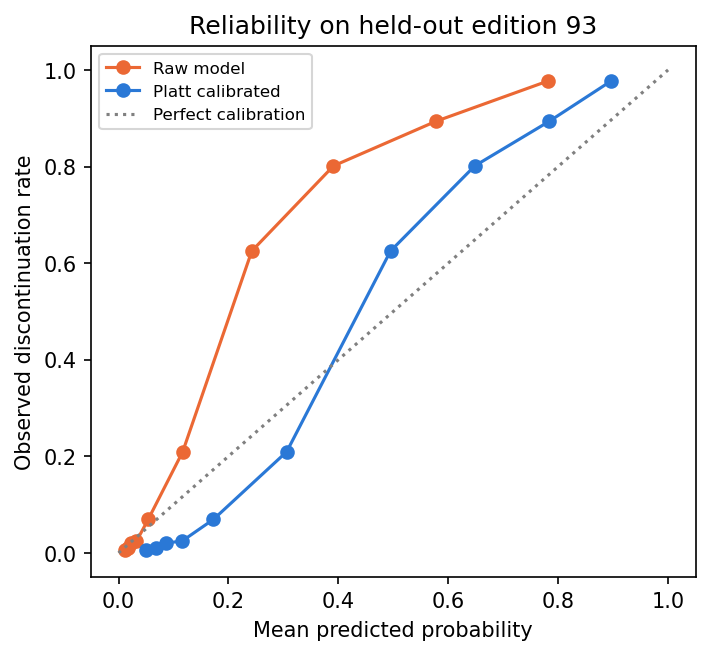

,evaluated_edition,method,observed_rate,mean_predicted,brier,log_loss,ece_10_quantile_bins,roc_auc
0,91,uncalibrated,0.3068,0.1361,0.2050,0.6467,0.1751,0.7945
1,91,platt,0.3068,0.2241,0.1801,0.5352,0.1100,0.7945
2,91,isotonic,0.3068,0.2124,0.1904,0.5849,0.1218,0.7722
3,92,uncalibrated,0.3024,0.1704,0.1812,0.5262,0.1350,0.8379
4,92,platt,0.3024,0.3253,0.1510,0.4521,0.0698,0.8379
5,92,isotonic,0.3024,0.3129,0.1515,0.4474,0.0601,0.8371


In [8]:
display(Image(FIG / f"calibration_before_after_h{H}.png"))
pd.read_csv(R / f"calibration_rolling_origin_h{H}.csv")[["evaluated_edition", "method", "observed_rate", "mean_predicted", "brier", "log_loss", "ece_10_quantile_bins", "roc_auc"]].round(4)

**Reading the evidence.** On the out-of-time checks, Platt scaling has a better Brier score than isotonic regression on editions 91 and 92; isotonic is slightly better on edition 92 log loss and calibration error. Platt was preferred because it also preserves the ranking and rescales SHAP values exactly. Calibration improves but is not perfect: on edition 93 the calibrated curve is still S-shaped, overstating risk in the low-to-middle range and understating it from about 0.5 upward.

## 3c. Risk bands

> **Scale used here: calibrated probabilities**

High is the max-F1 threshold (0.283). The Low floor (0.144) is the 5th percentile of calibrated out-of-fold scores among discontinued products: at most 5% of discontinued development products fall in Low. The 5% is a policy choice, and the tables below test how it holds up.

In [9]:
pd.read_csv(R / f"risk_bands_h{H}.csv").round(3)

,sample,band,n,share_of_products,mean_predicted,observed_rate,share_of_discontinued
0,development out-of-fold,Low,24717,0.374,0.079,0.043,0.050
1,development out-of-fold,Medium,12808,0.194,0.204,0.269,0.160
2,development out-of-fold,High,28518,0.432,0.593,0.594,0.790
3,held-out test,Low,11045,0.412,0.082,0.017,0.019
4,held-out test,Medium,3359,0.125,0.200,0.093,0.032
5,held-out test,High,12379,0.462,0.656,0.747,0.949


In [10]:
budgets = pd.read_csv(R / f"final_risk_band_budgets_h{H}.csv")
budgets[["sample", "miss_budget", "floor", "Low_share", "Low_observed_rate", "Medium_share", "Medium_observed_rate", "High_share", "High_observed_rate", "realised_miss_rate"]].round(3)

,sample,miss_budget,floor,Low_share,Low_observed_rate,Medium_share,Medium_observed_rate,High_share,High_observed_rate,realised_miss_rate
0,development out-of-fold (pooled),0.01,0.072,0.173,0.019,0.396,0.165,0.432,0.594,0.010
1,edition 90 (out-of-fold),0.01,0.072,0.170,0.039,0.326,0.075,0.503,0.668,0.018
2,edition 91 (out-of-fold),0.01,0.072,0.130,0.002,0.560,0.244,0.310,0.546,0.001
3,edition 92 (out-of-fold),0.01,0.072,0.219,0.013,0.293,0.104,0.487,0.552,0.010
4,edition 93 (held out),0.01,0.072,0.171,0.008,0.366,0.047,0.462,0.747,0.004
5,"edition 94 (live, no labels)",0.01,0.072,0.093,NaN,0.495,NaN,0.411,NaN,NaN
6,development out-of-fold (pooled),0.05,0.144,0.374,0.043,0.194,0.269,0.432,0.594,0.050
7,edition 90 (out-of-fold),0.05,0.144,0.359,0.049,0.138,0.098,0.503,0.668,0.048
8,edition 91 (out-of-fold),0.05,0.144,0.379,0.066,0.311,0.361,0.310,0.546,0.081
9,edition 92 (out-of-fold),0.05,0.144,0.385,0.016,0.128,0.216,0.487,0.552,0.020


In [11]:
stability = pd.read_csv(R / f"final_risk_band_stability_h{H}.csv")
display(stability[stability.kind.str.startswith("within")].pivot(index="edition", columns="miss_budget", values="floor").round(3))
stability[stability.kind.str.startswith("out-of-time")][["edition", "miss_budget", "floor", "threshold", "realised_miss_rate", "low_share", "low_observed_rate", "high_share", "high_observed_rate", "high_recall"]].round(3)

miss_budget,0.01,0.05,0.10
edition,,,
90,0.061,0.150,0.329
91,0.105,0.132,0.150
92,0.077,0.214,0.274


,edition,miss_budget,floor,threshold,realised_miss_rate,low_share,low_observed_rate,high_share,high_observed_rate,high_recall
9,91,0.01,0.031,0.363,0.000,0.087,0.002,0.195,0.616,0.393
10,92,0.01,0.075,0.371,0.009,0.216,0.013,0.398,0.575,0.756
11,93,0.01,0.072,0.283,0.004,0.171,0.008,0.462,0.747,0.949
12,91,0.05,0.096,0.363,0.099,0.399,0.076,0.195,0.616,0.393
13,92,0.05,0.141,0.371,0.019,0.376,0.015,0.398,0.575,0.756
14,93,0.05,0.144,0.283,0.019,0.412,0.017,0.462,0.747,0.949
15,91,0.10,0.265,0.363,0.515,0.742,0.213,0.195,0.616,0.393
16,92,0.10,0.172,0.371,0.025,0.405,0.018,0.398,0.575,0.756
17,93,0.10,0.183,0.283,0.026,0.467,0.020,0.462,0.747,0.949


**Reading the evidence.** When calibrator and floor are fitted on earlier editions only, a 5% budget realised miss rates of 9.9%, 1.9% and 1.9% on editions 91, 92 and 93. The budget therefore describes the development data and is not a guarantee: the first of those checks had only one edition to learn from. A 10% budget was unstable (51.5% missed on edition 91). A 1% budget was the most reliable but leaves only about 9% of edition 94 in Low, with half of it in Medium. The Medium band's observed rate varies widely by edition (9-36%), so it should be read as uncertain rather than as a stable rate.

## 3d. Generalisation

> **Scale used here: ranking metrics; identical on raw and calibrated scales**

In [12]:
pd.read_csv(R / f"final_generalisation_h{H}.csv").round(3)

,group,segment,n,positive_rate,roc_auc,pr_auc
0,chronological CV,edition 90: all,21408,0.367,0.905,0.844
1,chronological CV,edition 90: excluding fully discontinued depar...,15974,0.152,0.807,0.530
2,chronological CV,edition 90: new to range,4428,0.329,0.869,0.773
3,chronological CV,edition 90: returning,16980,0.377,0.916,0.863
4,chronological CV,edition 91: all,22659,0.307,0.794,0.630
5,chronological CV,edition 91: excluding fully discontinued depar...,22659,0.307,0.794,0.630
6,chronological CV,edition 91: new to range,7317,0.349,0.767,0.653
7,chronological CV,edition 91: returning,15342,0.287,0.807,0.617
8,chronological CV,edition 92: all,21976,0.302,0.838,0.623
9,chronological CV,edition 92: excluding fully discontinued depar...,21976,0.302,0.838,0.623


In [13]:
display(pd.read_csv(R / f"final_edition_level_h{H}.csv").round(3))
pd.read_csv(R / f"final_diagnostic_refits_h{H}.csv").round(3)

,edition,n,positive_rate,fully_discontinued_departments,share_in_those_departments,model_roc_auc,department_history_baseline_roc_auc,within_department_roc_auc,department_level_spearman_pred_vs_actual
0,90,21408,0.367,9,0.254,0.905,0.909,0.794,0.907
1,91,22659,0.307,0,0.000,0.794,0.677,0.781,0.574
2,92,21976,0.302,0,0.000,0.838,0.789,0.728,0.684
3,93,26783,0.364,10,0.218,0.952,0.902,0.892,0.785


,study,variant,edition,n,positive_rate,roc_auc,pr_auc,within_department_roc_auc
0,feature ablation,all 20 features,90,21408,0.367,0.905,0.844,NaN
1,feature ablation,all 20 features,91,22659,0.307,0.794,0.630,NaN
2,feature ablation,all 20 features,92,21976,0.302,0.838,0.623,NaN
3,feature ablation,all 20 features,93,26783,0.364,0.952,0.915,NaN
4,feature ablation,without HierarchyLevel2,90,21408,0.367,0.718,0.624,NaN
5,feature ablation,without HierarchyLevel2,91,22659,0.307,0.781,0.644,NaN
6,feature ablation,without HierarchyLevel2,92,21976,0.302,0.731,0.558,NaN
7,feature ablation,without HierarchyLevel2,93,26783,0.364,0.800,0.716,NaN
8,feature ablation,without all product category inputs,90,21408,0.367,0.688,0.598,NaN
9,feature ablation,without all product category inputs,91,22659,0.307,0.751,0.610,NaN


In [14]:
{k: final[k] for k in ["edition_93_department_cluster_bootstrap", "cv_department_cluster_bootstrap", "edition_93_exit_departments"]}

{'edition_93_department_cluster_bootstrap': {'roc_auc_95': [0.9312461957435065,
   0.9707952595717979],
  'pr_auc_95': [0.8366009705930842, 0.9655952596776131],
  'departments': 17},
 'cv_department_cluster_bootstrap': {'90': {'roc_auc_95': [0.8344329910226658,
    0.9504726108677886],
   'pr_auc_95': [0.7062906115729753, 0.9384136683512764],
   'departments': 26},
  '91': {'roc_auc_95': [0.676684096098068, 0.8879713367179565],
   'pr_auc_95': [0.5295126024422616, 0.7222311969908565],
   'departments': 17},
  '92': {'roc_auc_95': [0.7192835704919085, 0.8830609083439481],
   'pr_auc_95': [0.5154409057500017, 0.7054162046942573],
   'departments': 17}},
 'edition_93_exit_departments': {'departments': 10,
  'test_mean_raw_score_in_those_departments': 0.4813103581020222,
  'test_mean_raw_score_elsewhere': 0.1531732346938886,
  'training_rate_by_edition_those_departments': {'89': 0.16835114062951198,
   '90': 0.20858191831115191,
   '91': 0.5024351924587588,
   '92': 0.6349666881581775},
  

**Why edition 93 scores higher than cross-validation (measured contributors).**
- Editions 90 and 93 contain 9 and 10 departments discontinued in full (25% and 22% of rows); editions 91 and 92 contain none. Their ROC-AUC is 0.905 and 0.952 against 0.794 and 0.838. Excluding those departments gives 0.807 and 0.928.
- The 10 departments had training rates rising from 17% in edition 89 to 63% in edition 92, so the model scored them higher (mean raw score 0.48 against 0.15 elsewhere). None of them appears in edition 94.
- More training data does not explain it: training on only the last edition still gives 0.955.
- Even without those departments, edition 93 is higher than editions 91 and 92, and within-department ROC-AUC is higher (0.892 against 0.781 and 0.728). This data does not explain why.

**Generalisable signal or edition-specific pattern? Both.** Product-level signal exists: within-department ROC-AUC is 0.73-0.89, and products never seen in training score 0.936 on edition 93. But the model relies heavily on department membership: removing `HierarchyLevel2` reduces edition 93 ROC-AUC from 0.952 to 0.800, and predicting departments never seen in training gives 0.57-0.77. A department-history baseline alone reaches 0.68-0.91, and on edition 90 it matches the model (0.909 against 0.905). The results should be presented as ranking well within an established department mix, not as transferable to new categories. With only four evaluated editions, edition-to-edition uncertainty remains large.

## 4. Feature-group ablation and leakage investigation

In [15]:
pd.read_csv(R / f"ablation_h{H}.csv").round(4)

,variant,model,n_features,cv_pr_auc_mean,cv_pr_auc_std,cv_pr_auc_ed90,cv_pr_auc_ed91,cv_pr_auc_ed92,test_pr_auc,test_roc_auc
0,all features (primary),hist_gradient_boosting,20,0.6988,0.1025,0.8437,0.6300,0.6226,0.9147,0.9518
1,without forecast features,hist_gradient_boosting,16,0.6987,0.1195,0.8678,0.6150,0.6134,0.9004,0.9467
2,without prior-edition history,hist_gradient_boosting,17,0.6938,0.1044,0.8414,0.6230,0.6170,0.9043,0.9463
3,with Status (leakage investigation),hist_gradient_boosting,23,0.7909,0.0385,0.7892,0.7446,0.8388,0.9419,0.9645


- *Without forecast features*: tests whether planner forecasts (which could embed delisting intentions, like Status) drive performance.
- *Without prior-edition history*: value of the product's track record.
- *With Status*: the size of the jump quantifies how much of the outcome is already decided by planners.

## 5. Prediction horizon

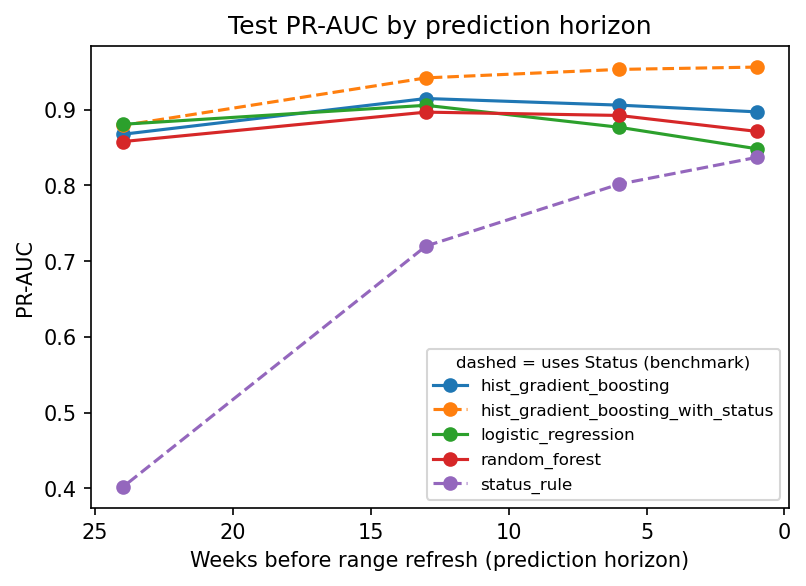

horizon,1,6,13,24
model,,,,
hist_gradient_boosting,0.897,0.906,0.915,0.867
hist_gradient_boosting_with_status,0.956,0.953,0.942,0.879
logistic_regression,0.848,0.877,0.906,0.881
random_forest,0.871,0.892,0.897,0.858
status_rule,0.837,0.802,0.720,0.402


In [16]:
hz = pd.read_csv(R / "horizon_comparison.csv")
display(Image(FIG / "horizon_comparison_pr_auc.png"))
hz.pivot(index="model", columns="horizon", values="pr_auc").round(3)

Hyperparameters were tuned at the primary horizon and reused at the other horizons (a documented simplification). Earlier predictions give more lead time; later ones use more data. The Status rule improves sharply towards the refresh as listing decisions are finalised, while the demand-based models are comparatively stable.

## 6. Interpretation

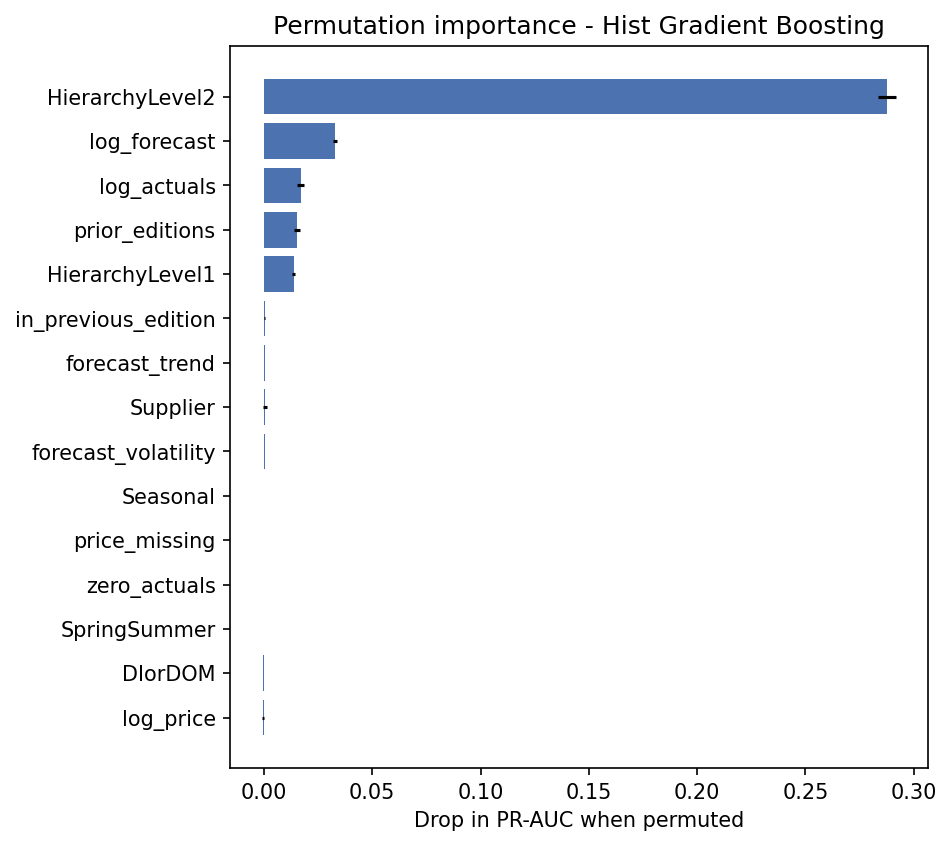

,feature,importance_mean,importance_std
0,HierarchyLevel2,0.2876,0.0043
1,log_forecast,0.0328,0.0009
2,log_actuals,0.0168,0.0017
3,prior_editions,0.0152,0.0014
4,HierarchyLevel1,0.0136,0.0008
5,in_previous_edition,0.0003,0.0002
6,forecast_trend,0.0003,0.0001
7,Supplier,0.0003,0.0009
8,forecast_volatility,0.0003,0.0000
9,Seasonal,0.0001,0.0000


In [17]:
display(Image(FIG / f"feature_importance_h{H}.png"))
pd.read_csv(R / f"feature_importance_h{H}.csv").head(10).round(4)

In [18]:
coef_path = R / f"logistic_coefficients_h{H}.csv"
if coef_path.exists():
    coefs = pd.read_csv(coef_path)
    display(coefs.head(15).round(3))

,feature,coefficient
0,HierarchyLevel1_48459,3.239
1,HierarchyLevel2_9740,-3.032
2,HierarchyLevel2_3163,-2.883
3,HierarchyLevel2_71089,-2.673
4,HierarchyLevel2_79976,-2.449
5,HierarchyLevel2_27781,-2.262
6,HierarchyLevel2_31435,-2.210
7,HierarchyLevel1_32577,-2.192
8,HierarchyLevel2_54877,2.125
9,HierarchyLevel1_40615,-2.107


Permutation importance is computed on raw input features (each categorical column permuted as a whole) on a sample of the test edition. Logistic regression coefficients are on standardised numeric inputs, so their magnitudes are comparable; positive coefficients increase discontinuation risk.

## 7. Segment analysis: new vs returning products

> **Scale used here: saved at training time with the raw threshold 0.103, which flags the same products as the calibrated threshold 0.283**

In [19]:
pd.read_csv(R / f"segment_metrics_h{H}.csv")[["segment", "n", "positive_rate", "roc_auc", "pr_auc", "precision", "recall", "f1"]].round(3)

,segment,n,positive_rate,roc_auc,pr_auc,precision,recall,f1
0,new to range,9648,0.467,0.939,0.930,0.713,0.963,0.820
1,returning product,17135,0.306,0.959,0.907,0.779,0.937,0.851


## 8. Error analysis on the test edition

> **Scale used here: deployed calibrated model; outcome labels use the calibrated threshold**

In [20]:
from product_discontinuation.predict import predict_weekly
bundle = load_bundle(model_path)
app_weekly = pd.read_parquet(config.PROCESSED_DIR / "app_weekly.parquet")
history = pd.read_parquet(config.PROCESSED_DIR / "edition_history.parquet")
test_weekly = app_weekly[app_weekly.CatEdition == config.TEST_EDITION]
feats, preds = predict_weekly(bundle, test_weekly.drop(columns=[config.TARGET]), history=history)
preds = preds.merge(test_weekly.groupby(config.GROUP_KEYS)[config.TARGET].first().astype(int).reset_index(), on=config.GROUP_KEYS)
preds["outcome"] = np.select([(preds.predicted_discontinued == 1) & (preds[config.TARGET] == 1),
                              (preds.predicted_discontinued == 1) & (preds[config.TARGET] == 0),
                              (preds.predicted_discontinued == 0) & (preds[config.TARGET] == 1)], ["TP", "FP", "FN"], "TN")
feats.merge(preds[config.GROUP_KEYS + ["outcome"]], on=config.GROUP_KEYS).groupby("outcome")[
    ["log_actuals", "log_forecast", "forecast_to_actual", "in_previous_edition", "weeks_in_edition"]].mean().round(3)

,log_actuals,log_forecast,forecast_to_actual,in_previous_edition,weeks_in_edition
outcome,,,,,
FN,3.112,3.779,0.667,0.666,11.664
FP,2.024,3.255,1.231,0.444,11.137
TN,4.192,4.580,0.388,0.755,11.872
TP,2.036,2.876,0.840,0.531,10.750


Missed discontinuations (FN) typically look like healthy sellers - this is consistent with delisting decisions depending on information not in the data, such as supplier decisions or range strategy, although the data cannot confirm that. This is a genuine limitation of demand-based prediction.